# Hyser: sEMG to force timing, forecast against baselines, calibration

**Data.** Hyser random task (PhysioNet `hd-semg` 2.0.0), subject 1, session 1, trials 1 and 2: 256 forearm HD-sEMG electrodes (four 8 × 8 grids, 2048 Hz) and the force of the five fingers (100 Hz).

Calibrate on one trial and test on the other, in both directions. At prediction time the models only use sEMG up to the current sample. Normalization, components, weights and model parameters come from the calibration trial.




In [1]:
import os
from pathlib import Path
REPO_DIR = Path(r"C:\Users\karly\Hyser\revel")
HYSER_DIR = r"C:\Users\karly\Hyser\random_dataset\subject01_session1"
FIG_DIR = str(REPO_DIR / "figures")
RES_DIR = str(REPO_DIR / "results")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)
TRIALS = (1, 2)

import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import butter, sosfilt, sosfiltfilt, welch
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from IPython.display import Image, display
warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
FS_EMG, FS_F = 2048, 100                  # Hz
FINGERS = ["thumb", "index", "middle", "ring", "little"]
GRIDS = ["ED", "EP", "FD", "FP"]          # extensor distal / proximal, flexor distal / proximal
TARGET = "middle"                         # finger used for forecasting and calibration
START, HMAX = 100, 20                     # skip the first 1 s; keep 200 ms at the end for future targets
HORIZONS_MS = [30, 50, 70, 100, 150, 200]
LAGS = (0, 3, 6)                          # EMG history: now, 30 ms and 60 ms ago
K_PCA = 16
ALPHAS = [1.0, 10.0, 100.0, 1000.0]
WIN_MS = 50                               # trailing RMS window
TAU_ACT_MS, TAU_DEACT_MS = 10.0, 40.0     # activation / deactivation time constants (Zajac 1989)
SEED = 7

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=path, width=900))
    print("saved", path)


setup()

## Reading the files and checking the electrodes

In [3]:
def read_hea(path):
    with open(path) as f:
        L = [l.strip() for l in f if l.strip() and not l.startswith("#")]
    name, nsig, fs, nsamp = L[0].split()[:4]
    sig = []
    for l in L[1:1 + int(nsig)]:
        p = l.split()
        g = p[2].split("/")[0]
        if "(" in g:
            gain, base = float(g[:g.index("(")]), int(g[g.index("(") + 1:g.index(")")])
        else:
            gain, base = float(g), (int(p[4]) if len(p) > 4 else 0)
        sig.append(dict(file=p[0], fmt=p[1], gain=gain if gain != 0 else 200.0, base=base,
                        name=p[8] if len(p) > 8 else f"ch{len(sig)}"))
    return dict(nsig=int(nsig), fs=float(fs.split("/")[0]), nsamp=int(nsamp), sig=sig)


def read_record(stem):
    """WFDB record (format 16) as samples x channels, in physical units."""
    h = read_hea(stem + ".hea")
    if any(s["fmt"] != "16" for s in h["sig"]):
        raise ValueError("only WFDB format 16 is supported")
    d = np.fromfile(os.path.join(os.path.dirname(stem), h["sig"][0]["file"]), dtype="<i2")
    if d.size != h["nsig"] * h["nsamp"]:
        raise ValueError(f"{stem}.dat is incomplete")
    d = d.reshape(h["nsamp"], h["nsig"]).astype(np.float64)
    g = np.array([s["gain"] for s in h["sig"]])
    b = np.array([s["base"] for s in h["sig"]])
    return ((d - b) / g).astype(np.float32), [s["name"] for s in h["sig"]]


def load_trial(n):
    emg, names = read_record(os.path.join(HYSER_DIR, f"random_raw_sample{n}"))
    force, _ = read_record(os.path.join(HYSER_DIR, f"random_force_sample{n}"))
    return emg, force.astype(np.float64), names


def channel_qc(emg, names):
    """Electrodes with abnormal amplitude, mains interference, spikes, or unlike their neighbours."""
    sos = butter(4, [20, 450], btype="band", fs=FS_EMG, output="sos")
    y = sosfilt(sos, emg, axis=0)[FS_EMG:]
    rms = np.sqrt(np.mean(y.astype(np.float64) ** 2, 0))
    f, P = welch(emg[FS_EMG:], fs=FS_EMG, nperseg=2048, axis=0)
    band = (f >= 20) & (f <= 450)
    line = np.zeros_like(f, bool)
    for k in range(50, 451, 50):
        line |= np.abs(f - k) <= 1
    line_ratio = P[line & band].sum(0) / P[band].sum(0)
    z = (y - y.mean(0)) / y.std(0)
    kurt = np.mean(z.astype(np.float64) ** 4, 0)
    c = np.vstack([np.zeros((1, y.shape[1])), np.cumsum(y.astype(np.float64) ** 2, 0)])
    w = int(0.05 * FS_EMG)
    env = np.sqrt((c[w::20] - c[:-w:20][:len(c[w::20])]) / w)
    zr, zk = np.zeros(len(names)), np.zeros(len(names))
    for G in GRIDS:
        idx = [i for i, nm in enumerate(names) if nm.startswith(G)]
        for v, out in [(np.log(rms), zr), (np.log(kurt), zk)]:
            med = np.median(v[idx]); mad = 1.4826 * np.median(np.abs(v[idx] - med))
            out[idx] = (v[idx] - med) / mad
    flags = {}
    for i, nm in enumerate(names):
        why = []
        if abs(zr[i]) > 5: why.append("amplitude")
        if line_ratio[i] > 0.3: why.append("mains interference")
        if zk[i] > 4 and kurt[i] > 50: why.append("spikes")
        if why: flags[nm] = why
    pos = {}
    for i, nm in enumerate(names):
        g, r, cc = nm.split("-")
        pos[(g, int(r), int(cc))] = i
    for (g, r, cc), i in pos.items():
        nb = [pos[(g, r + a, cc + b)] for a, b in [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]
              if (g, r + a, cc + b) in pos and names[pos[(g, r + a, cc + b)]] not in flags]
        if nb and np.corrcoef(env[:, i], np.median(env[:, nb], 1))[0, 1] < 0.5:
            flags.setdefault(names[i], []).append("unlike neighbours")
    return flags

## Features and models

In [4]:
def envelope(emg, win_ms=WIN_MS):
    """Causal: band-pass 20-450 Hz, then trailing RMS sampled at the force timestamps (EMG up to t only)."""
    sos = butter(4, [20, 450], btype="band", fs=FS_EMG, output="sos")
    x = sosfilt(sos, emg, axis=0).astype(np.float64) ** 2
    c = np.vstack([np.zeros((1, x.shape[1])), np.cumsum(x, 0)])
    n_f = int(np.floor(emg.shape[0] / FS_EMG * FS_F))
    w = max(1, int(round(win_ms / 1000 * FS_EMG)))
    idx = np.clip(np.floor(np.arange(n_f) / FS_F * FS_EMG).astype(int) + 1, 1, emg.shape[0])
    lo = np.clip(idx - w, 0, None)
    return np.sqrt((c[idx] - c[lo]) / np.maximum(idx - lo, 1)[:, None])


class FrontEnd:
    """z-score and PCA, both fitted on calibration samples."""
    def __init__(self, k=K_PCA):
        self.k = k

    def fit(self, L, idx):
        self.mu, self.sd = L[idx].mean(0), L[idx].std(0) + 1e-9
        self.pca = PCA(n_components=self.k, random_state=0).fit((L[idx] - self.mu) / self.sd)
        self.scale = np.sqrt(self.pca.explained_variance_) + 1e-9
        return self

    def transform(self, L):
        return self.pca.transform((L - self.mu) / self.sd) / self.scale


def shift(Z, L):
    out = np.zeros_like(Z)
    if L == 0:
        return Z.copy()
    out[L:] = Z[:-L]
    return out


def design(Z, lags=LAGS):
    return np.hstack([shift(Z, L) for L in lags])


def eval_idx(n):
    return np.arange(START, n - HMAX)


def blocked_folds(idx, n=5, gap=50, h=0):
    for b in np.array_split(idx, n):
        yield idx[(idx < b[0] - gap - h) | (idx > b[-1] + h + gap)], b


def select_alpha(X, y, idx, h):
    """Ridge penalty chosen by blocked cross-validation inside the calibration trial."""
    best = None
    for a in ALPHAS:
        sse = 0.0
        for tr, va in blocked_folds(idx, h=h):
            sse += np.sum((Ridge(alpha=a).fit(X[tr], y[tr + h]).predict(X[va]) - y[va + h]) ** 2)
        if best is None or sse < best[1]:
            best = (a, sse)
    return best[0]


def crossfit(X, y, idx, h, alpha):
    """Out-of-fold predictions on the calibration trial."""
    P = np.full(len(y), np.nan)
    for tr, va in blocked_folds(idx, h=h):
        P[va] = Ridge(alpha=alpha).fit(X[tr], y[tr + h]).predict(X[va])
    return P


def r2(p, y):
    return float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))


def rest_level(y):
    return float(np.median(y[:50]))


def phase_labels(y, rest, ref):
    """rising / falling / steady / rest at each force sample (offline labels, centred smoothing)."""
    a = np.abs(y - rest)
    sm = np.convolve(a, np.ones(5) / 5, mode="same")
    d = np.zeros_like(sm)
    d[5:-5] = sm[10:] - sm[:-10]
    thr, near = 0.15 * ref, 0.10 * ref
    lab = np.full(len(y), "steady", dtype=object)
    lab[d > thr] = "rising"
    lab[d < -thr] = "falling"
    lab[(np.abs(d) <= thr) & (sm <= near)] = "rest"
    return lab

## Reduced physiological model

In [5]:
def activation(u, u0, tau_act=TAU_ACT_MS, tau_deact=TAU_DEACT_MS):
    """First-order activation dynamics: faster rise than relaxation, around the rest level u0."""
    aa, ad = 1 - np.exp(-10.0 / tau_act), 1 - np.exp(-10.0 / tau_deact)
    a = np.empty_like(u)
    a[0] = u[0]
    for n in range(1, len(u)):
        al = aa if abs(u[n] - u0) > abs(a[n - 1] - u0) else ad
        a[n] = a[n - 1] + al * (u[n] - a[n - 1])
    return a


def curve(a, u0, b, k, p):
    return b + k * np.sign(a - u0) * np.abs(a - u0) ** p


def curve_fit(a, y, u0, p):
    g = np.sign(a - u0) * np.abs(a - u0) ** p
    coef, *_ = np.linalg.lstsq(np.column_stack([np.ones_like(g), g]), y, rcond=None)
    return coef


class Physio:
    """Baseline 4. Drive estimate (ridge readout of the EMG) -> activation dynamics -> person-specific curve
    F(t + d) = b + k sgn(a - u0)|a - u0|^p. Beyond the delay d the activation state is advanced with the drive
    held at its last value."""
    D_GRID = list(range(0, 16))                                    # delay d: 0-150 ms
    P_GRID = [round(x, 2) for x in np.arange(0.5, 2.01, 0.1)]
    TAU_GRID = [(10, 40), (10, 80), (20, 80), (20, 120), (40, 120), (40, 160), (40, 240)]

    def __init__(self, fit_tau=False):
        self.fit_tau = fit_tau

    def fit(self, Z, y, idx, rest):
        self.u0 = rest
        best, prof = None, {}
        taus = self.TAU_GRID if self.fit_tau else [(TAU_ACT_MS, TAU_DEACT_MS)]
        for d in self.D_GRID:
            w = Ridge(alpha=10.0).fit(Z[idx], y[idx + d])
            u = w.predict(Z)
            for ta, td in taus:
                a = activation(u, rest, ta, td)
                for p in self.P_GRID:
                    b, k = curve_fit(a[idx], y[idx + d], rest, p)
                    sc = r2(curve(a[idx], rest, b, k, p), y[idx + d])
                    prof[(d, p)] = max(sc, prof.get((d, p), -np.inf))
                    if best is None or sc > best[0]:
                        best = (sc, d, p, b, k, w, ta, td)
        _, self.d, self.p, self.b, self.k, self.w, self.tau_act, self.tau_deact = best
        self.delay_profile = np.array([prof[(d, self.p)] for d in self.D_GRID])   # calibration fit for each delay
        return self

    def predict(self, Z, h):
        u = self.w.predict(Z)
        a = activation(u, self.u0, self.tau_act, self.tau_deact)
        if h <= self.d:
            aa = shift(a[:, None], self.d - h)[:, 0]
        else:
            tau = np.where(np.abs(u - self.u0) > np.abs(a - self.u0), self.tau_act, self.tau_deact)
            aa = u + (a - u) * np.exp(-(h - self.d) * 10.0 / tau)
        return curve(aa, self.u0, self.b, self.k, self.p)

## Load both trials

In [6]:
TR, bad = {}, set()
for n in TRIALS:
    emg, force, names = load_trial(n)
    flags = channel_qc(emg, names)
    bad |= set(flags)
    TR[n] = dict(emg=emg, F=force)
    print(f"trial {n}: {emg.shape[1]} electrodes, {emg.shape[0] / FS_EMG:.0f} s; flagged: {', '.join(sorted(flags)) or 'none'}")
keep = np.array([nm not in bad for nm in names])
for n in TRIALS:
    TR[n]["L"] = np.log(envelope(TR[n]["emg"][:, keep]) + 1e-7)    # causal log envelope at 100 Hz
print("electrodes used:", int(keep.sum()), "| excluded:", ", ".join(sorted(bad)))

trial 1: 256 electrodes, 25 s; flagged: ED-3-8, ED-4-8, EP-1-6, EP-1-7, FD-8-2
trial 2: 256 electrodes, 25 s; flagged: ED-3-8, ED-4-8, EP-1-6, EP-1-7, FD-8-2
electrodes used: 251 | excluded: ED-3-8, ED-4-8, EP-1-6, EP-1-7, FD-8-2


## Figure 1 · sEMG-to-force timing

Offline measurement at the first contraction from rest in each trial: the first time the sEMG activity (all electrodes) and the finger force (change from rest, five fingers) stay above rest noise (mean + 5 SD of 0.3–0.9 s) for 50 ms.

In [7]:
def emg_activity(emg):
    """Offline sEMG activity: zero-phase band-pass, 20 ms centred RMS, averaged over electrodes."""
    sos = butter(4, [20, 450], btype="band", fs=FS_EMG, output="sos")
    acc, w = np.zeros(emg.shape[0]), int(0.02 * FS_EMG)
    for chunk in np.array_split(np.arange(emg.shape[1]), 8):
        x = sosfiltfilt(sos, emg[:, chunk].astype(np.float64), axis=0) ** 2
        c = np.vstack([np.zeros((1, x.shape[1])), np.cumsum(x, 0)])
        i = np.arange(x.shape[0]); lo = np.clip(i - w // 2, 0, None); hi = np.clip(i + w // 2, None, x.shape[0])
        acc += np.sqrt((c[hi] - c[lo]) / (hi - lo)[:, None]).sum(1)
    return acc / emg.shape[1]


def onset(sig, t, k_sd=5.0, dur=0.05):
    r = (t > 0.3) & (t < 0.9)
    above = sig > sig[r].mean() + k_sd * sig[r].std()
    nn = int(dur / (t[1] - t[0]))
    for i in np.where(above & (t > 0.9))[0]:
        if above[i:i + nn].all():
            return float(t[i])


TIMING = {}
for n in TRIALS:
    act = emg_activity(TR[n]["emg"][:, keep])
    F = TR[n]["F"]
    force = np.abs(F - np.median(F[30:90], 0)).sum(1)
    te, tf = np.arange(len(act)) / FS_EMG, np.arange(len(force)) / FS_F
    t1 = np.arange(0, len(force) / FS_F, 0.001)
    e_on, f_on = onset(act, te), onset(np.interp(t1, tf, force), t1)
    TIMING[n] = dict(emg_onset_s=e_on, force_onset_s=f_on, delay_ms=int(round(1000 * (f_on - e_on))), te=te, act=act, tf=tf, force=force)
    print(f"trial {n}: EMG onset {e_on:.3f} s, force onset {f_on:.3f} s -> EMG {TIMING[n]['delay_ms']} ms before force")

trial 1: EMG onset 1.728 s, force onset 1.770 s -> EMG 42 ms before force
trial 2: EMG onset 1.166 s, force onset 1.217 s -> EMG 51 ms before force


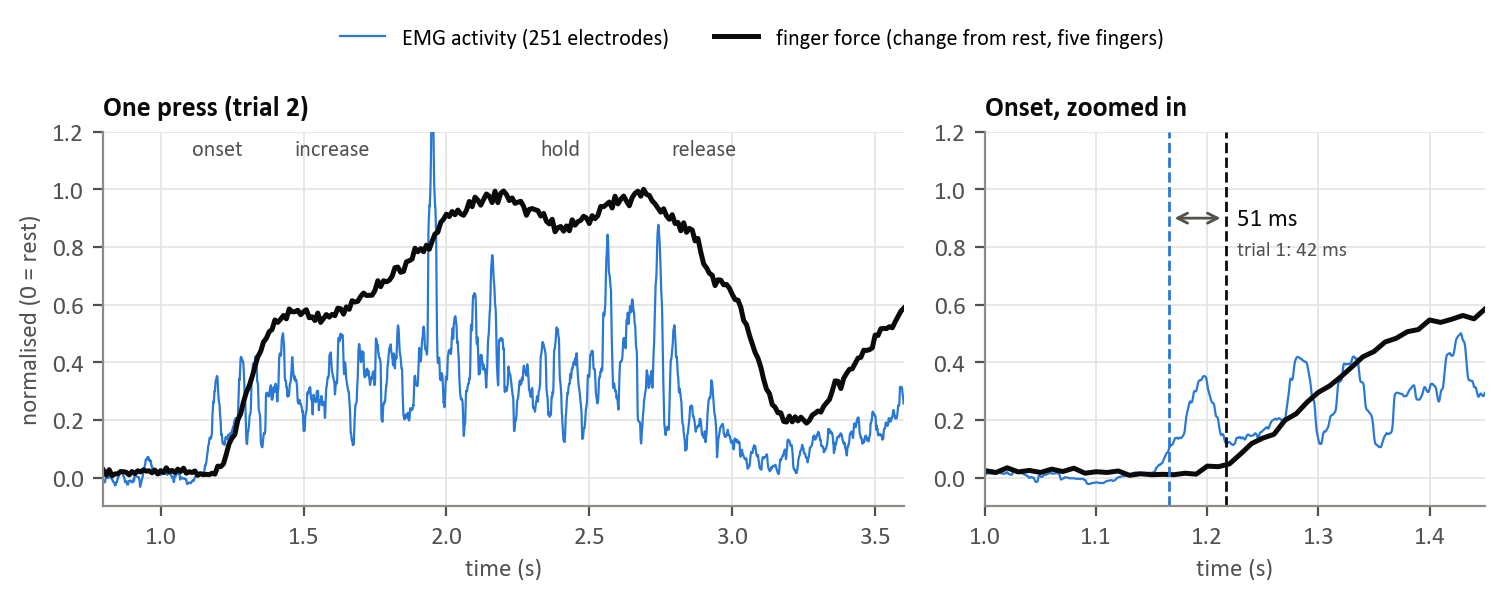

saved C:\Users\karly\Hyser\revel\figures\figure1.png


In [8]:
EX = 2                                                    # trial shown
WIN_A, WIN_B = (0.8, 3.6), (1.0, 1.45)                    # whole press, onset zoom (s)
LABELS = {"onset": 1.2, "increase": 1.6, "hold": 2.4, "release": 2.9}   # label positions for this press (s)

T = TIMING[EX]
te, act, tf, force = T["te"], T["act"], T["tf"], T["force"]
we, wf = (te >= WIN_A[0]) & (te <= WIN_A[1]), (tf >= WIN_A[0]) & (tf <= WIN_A[1])
rest = act[(te > 0.3) & (te < 0.9)].mean()
emg_n = (act - rest) / (np.percentile(act[we], 99.5) - rest)
force_n = force / force[wf].max()

fig, axs = plt.subplots(1, 2, figsize=(7.6, 2.7), gridspec_kw=dict(width_ratios=[1.6, 1]))
for ax, (a, b) in zip(axs, (WIN_A, WIN_B)):
    me, mf = (te >= a) & (te <= b), (tf >= a) & (tf <= b)
    ax.plot(te[me], emg_n[me], color=BLUE, lw=0.8, label="EMG activity (251 electrodes)")
    ax.plot(tf[mf], force_n[mf], color=INK, lw=1.8, label="finger force (change from rest, five fingers)")
    ax.set_xlim(a, b); ax.set_ylim(-0.1, 1.2); ax.set_xlabel("time (s)")
axs[0].set_ylabel("normalised (0 = rest)")
for name, x in LABELS.items():
    axs[0].text(x, 1.12, name, ha="center", fontsize=8, color=INK2)
axs[0].set_title(f"One press (trial {EX})")
ax = axs[1]
ax.axvline(T["emg_onset_s"], color=BLUE, lw=1, ls="--")
ax.axvline(T["force_onset_s"], color=INK, lw=1, ls="--")
ax.annotate("", xy=(T["force_onset_s"], 0.9), xytext=(T["emg_onset_s"], 0.9), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
ax.text(T["force_onset_s"] + 0.01, 0.9, f"{T['delay_ms']} ms", va="center", fontsize=9, color=INK)
for n in TRIALS:
    if n != EX:
        ax.text(T["force_onset_s"] + 0.01, 0.79, f"trial {n}: {TIMING[n]['delay_ms']} ms", va="center", fontsize=7.5, color=INK2)
ax.set_title("Onset, zoomed in")
fig.tight_layout(w_pad=1.2)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save(fig, "figure1.png")

## Figure 2 · Forecast against the baselines, by horizon and phase

Middle finger force at *t + h*, predicted at *t*. sEMG forecast: ridge regression on the causal sEMG features (now, 30 and 60 ms ago). Baseline 1: the model's own current force estimate, repeated. Baseline 2: the last measured force, repeated (offline reference). Baseline 3: trend of the estimate (damping chosen on the calibration trial). Baseline 4: reduced physiological model with calibrated dynamics. Phases come from the measured force; error is the RMS error in % of a typical press (95th percentile of the force change in the test trial), pooled over both directions. The figure shows the sEMG forecast and baselines 1 and 2; the table has all four baselines.

In [9]:
def trend(pnow, h, phi):
    s = np.convolve(pnow, np.ones(5) / 5, mode="full")[:len(pnow)]          # causal smoothing
    return pnow + phi * (s - shift(s[:, None], 10)[:, 0]) / 10.0 * h


MODELS = ["EMG forecast", "baseline 1: own estimate", "baseline 2: measured force", "baseline 3: trend", "baseline 4: physiological"]
PHASES = ["rising", "steady", "falling"]
j = FINGERS.index(TARGET)
SSE = {}
for cal, tst in [(TRIALS[0], TRIALS[1]), (TRIALS[1], TRIALS[0])]:
    yA, yB = TR[cal]["F"][:, j], TR[tst]["F"][:, j]
    idxA, idxB = eval_idx(len(yA)), eval_idx(len(yB))
    fe = FrontEnd().fit(TR[cal]["L"], idxA)
    ZA, ZB = fe.transform(TR[cal]["L"]), fe.transform(TR[tst]["L"])
    XA, XB = design(ZA), design(ZB)
    restA, restB = rest_level(yA), rest_level(yB)
    phase = phase_labels(yB, restB, np.percentile(np.abs(yA[idxA] - restA), 95))
    scale = np.percentile(np.abs(yB[idxB] - restB), 95)
    a0 = select_alpha(XA, yA, idxA, 0)
    now = Ridge(alpha=a0).fit(XA[idxA], yA[idxA]).predict(XB)
    nowA = np.nan_to_num(crossfit(XA, yA, idxA, 0, a0))
    phys = Physio(fit_tau=True).fit(ZA, yA, idxA, restA)
    print(f"calibrate {cal} -> test {tst}: physiological model d {phys.d * 10} ms, tau act/relax {phys.tau_act}/{phys.tau_deact} ms, p {phys.p}")
    for hm in HORIZONS_MS:
        h = hm // 10
        P = Ridge(alpha=select_alpha(XA, yA, idxA, h)).fit(XA[idxA], yA[idxA + h]).predict(XB)
        phis = [0, 0.25, 0.5, 0.75, 1.0]
        ok = idxA[15:]
        phi = phis[int(np.argmin([np.mean((trend(nowA, h, f)[ok] - yA[ok + h]) ** 2) for f in phis]))]
        pred = dict(zip(MODELS, [P, now, yB, trend(now, h, phi), phys.predict(ZB, h)]))
        Y, lab = yB[idxB + h], phase[idxB + h]
        for p in PHASES:
            m = lab == p
            for nm, v in pred.items():
                s, c = SSE.get((p, nm, hm), (0.0, 0))
                SSE[(p, nm, hm)] = (s + np.sum(((v[idxB][m] - Y[m]) / scale) ** 2), c + int(m.sum()))
ERR = {p: {nm: [100 * np.sqrt(SSE[(p, nm, hm)][0] / SSE[(p, nm, hm)][1]) for hm in HORIZONS_MS] for nm in MODELS} for p in PHASES}
for p in PHASES:
    print(f"\n{p}  (error, % of a typical press)   h = " + "  ".join(f"{hm:>4}" for hm in HORIZONS_MS))
    for nm in MODELS:
        print(f"  {nm:30s}" + "  ".join(f"{v:4.1f}" for v in ERR[p][nm]))

calibrate 1 -> test 2: physiological model d 40 ms, tau act/relax 40/160 ms, p 1.5
calibrate 2 -> test 1: physiological model d 50 ms, tau act/relax 40/240 ms, p 1.7

rising  (error, % of a typical press)   h =   30    50    70   100   150   200
  EMG forecast                  26.6  26.5  27.6  30.2  37.2  46.2
  baseline 1: own estimate      26.7  26.7  27.8  31.1  38.9  48.8
  baseline 2: measured force    14.1  22.5  30.0  39.2  51.7  60.8
  baseline 3: trend             26.7  26.7  27.8  31.1  38.9  48.8
  baseline 4: physiological     26.6  26.7  28.2  31.6  38.6  46.6

steady  (error, % of a typical press)   h =   30    50    70   100   150   200
  EMG forecast                  22.9  22.3  21.9  22.0  23.1  24.6
  baseline 1: own estimate      23.2  22.9  22.8  23.2  24.0  24.9
  baseline 2: measured force     2.8   4.7   7.0  10.8  16.3  22.1
  baseline 3: trend             23.2  22.9  22.8  23.2  24.0  24.9
  baseline 4: physiological     22.7  22.7  23.1  24.0  26.1  28.0

fal

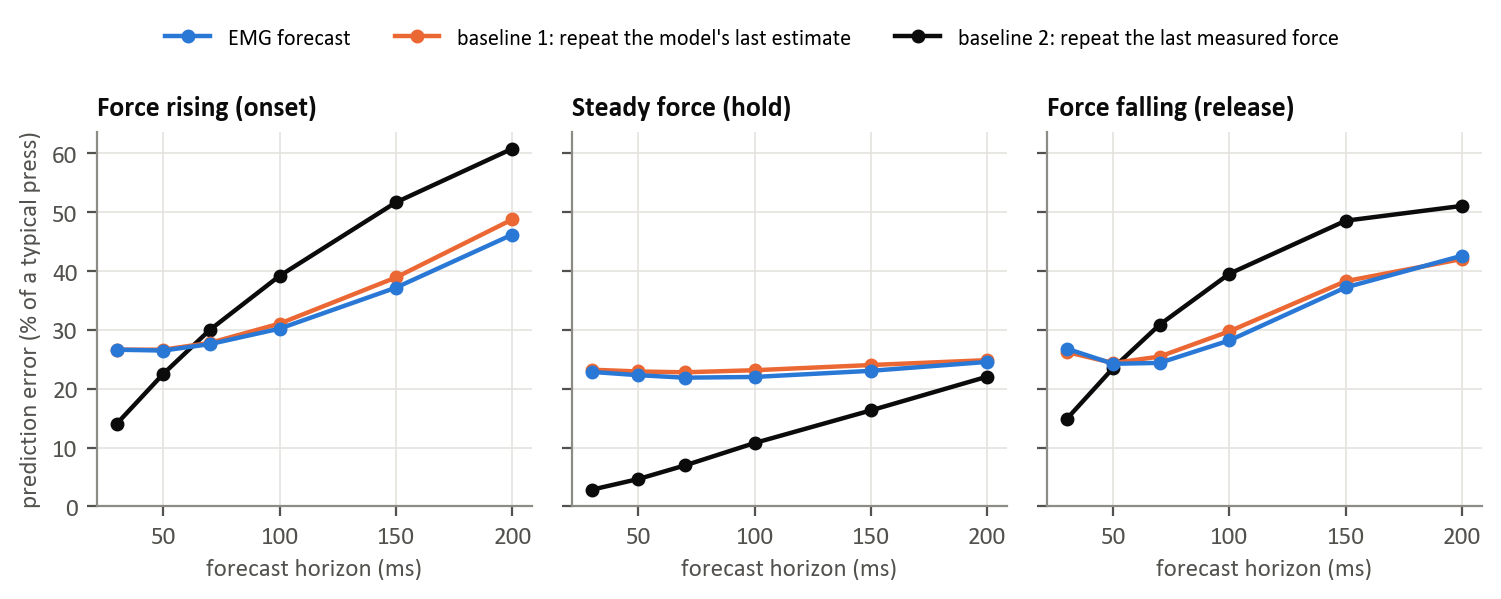

saved C:\Users\karly\Hyser\revel\figures\figure2.png


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(7.6, 2.7), sharey=True)
SHOW = [("baseline 2: measured force", INK, "baseline 2: repeat the last measured force"),
        ("baseline 1: own estimate", ORANGE, "baseline 1: repeat the model's last estimate"),
        ("EMG forecast", BLUE, "EMG forecast")]
for ax, p, title in zip(axs, PHASES, ["Force rising (onset)", "Steady force (hold)", "Force falling (release)"]):
    for nm, col, lab in SHOW:
        ax.plot(HORIZONS_MS, ERR[p][nm], color=col, marker="o", ms=4, label=lab)
    ax.set_title(title); ax.set_xlabel("forecast horizon (ms)"); ax.set_xticks([50, 100, 150, 200])
axs[0].set_ylabel("prediction error (% of a typical press)")
axs[0].set_ylim(0, None)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h[::-1], l[::-1], loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "figure2.png")

## Figure 4 · Calibration: steady against changing force

From the calibration trial, the same number of labelled force samples is taken from steady force (hold like), from changing force (ramp like, rising or falling) or from the whole trial (mixed). With each set: (a) the reduced physiological model (literature dynamics) is fitted for every sEMG to force delay, and (b) the sEMG forecast (h = 50 ms) is trained and tested on the other trial. Unlabelled sEMG of the whole calibration trial is used for normalization.

In [11]:
CAL = {}
rng = np.random.default_rng(SEED)
for cal, tst in [(TRIALS[0], TRIALS[1]), (TRIALS[1], TRIALS[0])]:
    yA, yB = TR[cal]["F"][:, j], TR[tst]["F"][:, j]
    full, idxB = eval_idx(len(yA)), eval_idx(len(yB))
    restA = rest_level(yA)
    lab = phase_labels(yA, restA, np.percentile(np.abs(yA[full] - restA), 95))
    groups = {"steady": full[np.isin(lab[full], ["steady", "rest"])],
              "changing": full[np.isin(lab[full], ["rising", "falling"])],
              "mixed": full}
    nsub = min(len(groups["steady"]), len(groups["changing"]), 600)
    fe = FrontEnd().fit(TR[cal]["L"], full)
    ZA, ZB = fe.transform(TR[cal]["L"]), fe.transform(TR[tst]["L"])
    XA, XB = design(ZA), design(ZB)
    h = 5
    for g, ix in groups.items():
        sel = np.sort(rng.choice(ix, nsub, replace=False))
        prof = Physio().fit(ZA, yA, sel, restA).delay_profile
        P = Ridge(alpha=select_alpha(XA, yA, sel, h)).fit(XA[sel], yA[sel + h]).predict(XB)
        CAL[(cal, g)] = dict(n=int(nsub), delay_ms=[d * 10 for d in Physio.D_GRID], delay_profile=prof.tolist(),
                            fit_range_over_delays=float(prof.max() - prof.min()), best_delay_ms=int(10 * np.argmax(prof)),
                            r2_test=r2(P[idxB], yB[idxB + h]))
        print(f"calibrate {cal} -> test {tst}, {g:8s} ({nsub} samples): fit range over delays {prof.max() - prof.min():.3f}, "
              f"best delay {10 * np.argmax(prof)} ms, R2 on trial {tst}: {CAL[(cal, g)]['r2_test']:.2f}")

calibrate 1 -> test 2, steady   (577 samples): fit range over delays 0.035, best delay 80 ms, R2 on trial 2: 0.65
calibrate 1 -> test 2, changing (577 samples): fit range over delays 0.249, best delay 60 ms, R2 on trial 2: 0.56
calibrate 1 -> test 2, mixed    (577 samples): fit range over delays 0.103, best delay 70 ms, R2 on trial 2: 0.70
calibrate 2 -> test 1, steady   (210 samples): fit range over delays 0.036, best delay 110 ms, R2 on trial 1: 0.79
calibrate 2 -> test 1, changing (210 samples): fit range over delays 0.164, best delay 140 ms, R2 on trial 1: 0.70
calibrate 2 -> test 1, mixed    (210 samples): fit range over delays 0.105, best delay 110 ms, R2 on trial 1: 0.78


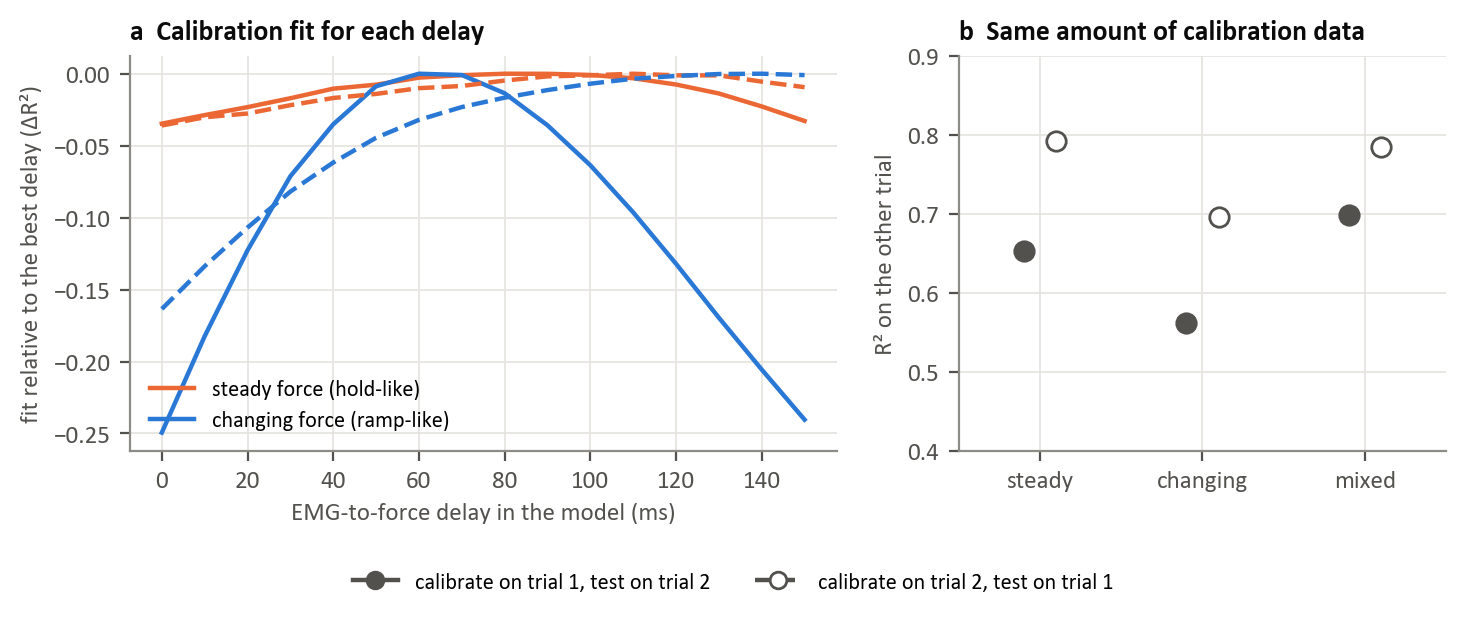

saved C:\Users\karly\Hyser\revel\figures\figure4.png


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.8), gridspec_kw=dict(width_ratios=[1.45, 1]))
ax = axs[0]
for cal, ls in zip(TRIALS, ("-", "--")):
    for g, col in (("steady", ORANGE), ("changing", BLUE)):
        pr = np.array(CAL[(cal, g)]["delay_profile"])
        ax.plot(CAL[(cal, g)]["delay_ms"], pr - pr.max(), color=col, ls=ls)
ax.set_xlabel("EMG-to-force delay in the model (ms)"); ax.set_ylabel("fit relative to the best delay (\u0394R\u00b2)")
ax.set_title("a  Calibration fit for each delay")
ax.legend(handles=[Line2D([], [], color=ORANGE, label="steady force (hold-like)"),
                   Line2D([], [], color=BLUE, label="changing force (ramp-like)")], loc="lower left")
ax = axs[1]
x = np.arange(3)
for cal, off, mfc in zip(TRIALS, (-0.1, 0.1), (INK2, "white")):
    ax.plot(x + off, [CAL[(cal, g)]["r2_test"] for g in ("steady", "changing", "mixed")], "o", color=INK2, mfc=mfc, ms=7, ls="none")
ax.set_xticks(x); ax.set_xticklabels(["steady", "changing", "mixed"]); ax.set_xlim(-0.5, 2.5); ax.set_ylim(0.4, 0.9)
ax.set_ylabel("R\u00b2 on the other trial"); ax.set_title("b  Same amount of calibration data")
fig.tight_layout(w_pad=1.5)
fig.legend(handles=[Line2D([], [], color=INK2, ls="-", marker="o", mfc=INK2, label="calibrate on trial 1, test on trial 2"),
                    Line2D([], [], color=INK2, ls="--", marker="o", mfc="white", label="calibrate on trial 2, test on trial 1")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.0))
save(fig, "figure4.png")

## Save the numbers

In [13]:
RES = dict(excluded_electrodes=sorted(bad),
           timing={n: {k: v for k, v in TIMING[n].items() if k not in ("te", "act", "tf", "force")} for n in TRIALS},
           forecast_error_percent=dict(horizons_ms=HORIZONS_MS, by_phase=ERR),
           calibration={f"calibrate{c}_{g}": v for (c, g), v in CAL.items()})
with open(os.path.join(RES_DIR, "hyser.json"), "w") as f:
    json.dump(RES, f, indent=1, default=float)
print("saved", os.path.join(RES_DIR, "hyser.json"))

saved C:\Users\karly\Hyser\revel\results\hyser.json
